In [ ]:
"""
code to plot and compare difference of hypoxia metrics between bias-corrected and original model
"""

In [1]:
# %matplotlib inline
# %matplotlib notebook
import matplotlib.pyplot as plt
import cmocean
from matplotlib.colors import TwoSlopeNorm
from matplotlib import ticker
from matplotlib import colors
# Set global font sizes for all plots, now all subsequent plots will follow these settings
import matplotlib.dates as mdates
from scipy.stats import ttest_ind
import xarray as xr
import numpy as np
import pandas as pd
from datetime import datetime
from lo_tools import Lfun
from lo_tools import plotting_functions as pfun

plt.style.use('default')

plt.rcParams.update({
    'axes.labelsize': 17,          # Labels font size
    'xtick.labelsize': 13,         # X-axis ticks font size
    'ytick.labelsize': 15,         # Y-axis ticks font size
    'axes.labelweight': 'bold',    # Bold axis labels
    'xtick.direction': 'out',       # X-axis tick direction
    'ytick.direction': 'out',       # Y-axis tick direction
    'font.size': 15,               # Default font size for other text
    'xtick.major.size': 6,     # <-- Length of major x ticks (in points)
    'ytick.major.size': 4,     # <-- Length of major y ticks
    'xtick.minor.size': 3,     # <-- Length of minor x ticks
    'ytick.minor.size': 3,     # <-- Length of minor y ticks

})
Ldir = Lfun.Lstart()

In [3]:
gtx = 'cas2k_v4_lo2b'
fod1 = 'bias_corrected'
in_dir0 = Ldir['LOo'] / 'extract'/ gtx / 'box' / fod1

In [4]:
# turn on and off different trials
add_hake_hpic_trawl = True
cast_split = True
cast_balanced = True
use_z_fraction = True
benthic_aware = False
hypoxia_aware = False
hypoxia_shelf_aware = False
hypoxia_two_tier_shelf_aware = True
hypoxia_shelf_smooth_aware = False
remove_NO3 = True

if add_hake_hpic_trawl:
    runame = 'with_hake_hpic_trawl'
    if cast_split:
        name = 'cid_split'
        if cast_balanced:
            name += '_cast_balanced'
            if cast_balanced and use_z_fraction:
                name += '_z_fraction'
            if cast_balanced and benthic_aware:
                name += '_benthic_aware'
            if cast_balanced and hypoxia_aware:
                name += '_hypoxia_aware'
            if cast_balanced and hypoxia_shelf_aware:
                name += '_hypoxia_shelf_aware'
            if cast_balanced and hypoxia_shelf_smooth_aware:
                name += '_hypoxia_shelf_smooth_aware'
            if cast_balanced and hypoxia_two_tier_shelf_aware:
                name += '_hypoxia_two_tier_shelf_aware'
            if remove_NO3:
                name += '_no_NO3'

    else:
        name = ''

in_dir = in_dir0/ runame / name
fig_dir = in_dir / 'figures'

In [8]:
testing = False
if testing:
    year_list = [1993]
    # year_list = np.arange(1998,2001)
else:
    year_list = np.arange(1993,2023)

In [9]:
# read all files
files = [
    f"{in_dir/'hypoxia'}/hypoxia_daily_bot_{yr}.nc"
    for yr in year_list
]

ds_daily = xr.open_mfdataset(
    sorted(files),
    combine='nested',
    concat_dim='ocean_time',
    preprocess=lambda x: x[['hyp_area', 'hyp_area_corrected']],
    parallel=True
).sortby('ocean_time')

In [48]:
# Select periods and compare the first decade and last decade
hyp_1993_2002 = ds_daily['hyp_area'].sel(
    ocean_time=slice('1993-01-01', '2002-12-31')
).mean()

hyp_2013_2022 = ds_daily['hyp_area'].sel(
    ocean_time=slice('2013-01-01', '2022-12-31')
).mean()

# If you want the same units as your plot (divided by 10e6)
hyp_1993_2002_plot = hyp_1993_2002 / 10e7
hyp_2013_2022_plot = hyp_2013_2022 / 10e7

print('1993–2002 mean:', hyp_1993_2002.values)
print('2013–2022 mean:', hyp_2013_2022.values)

print('1993–2002 mean:', hyp_1993_2002_plot.values)
print('2013–2022 mean:', hyp_2013_2022_plot.values)

1993–2002 mean: 449293858.91485494
2013–2022 mean: 980170895.4705666
1993–2002 mean: 4.492938589148549
2013–2022 mean: 9.801708954705667


#### plot daily time series of total hypoxia area along OR-WA coast

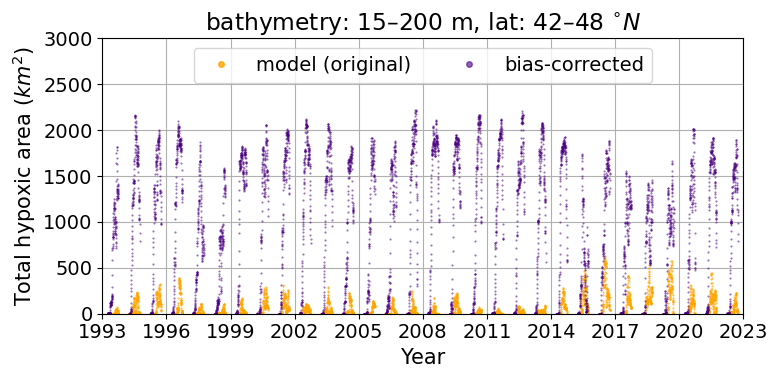

In [47]:
##
outname = f'plot_{gtx}_WA-OR_bot_hypoxic_area_{year_list[0]}_{year_list[-1]}.png'
outfile = fig_dir / outname

pfun.start_plot(figsize=(8,4))
fig = plt.figure()
ax = fig.add_subplot()
# temp.mean(('xi_rho', 'eta_rho')).plot()

ax.plot(
    ds_daily.ocean_time.values,
    ds_daily['hyp_area'].values / 10e6,
    color='orange',
    linestyle='None',
    marker='.',
    markersize=1,
    alpha=0.8,
    label='model (original)'
)

ax.plot(
    ds_daily.ocean_time.values,
    ds_daily['hyp_area_corrected'].values / 10e6,
    color='indigo',
    linestyle='None',
    marker='.',
    markersize=1,
    alpha=0.6,
    label='bias-corrected'
)

# ax.set_xlim(pd.Timestamp(temp.time[0].values), pd.Timestamp(temp.time[-1].values))
ax.set_xlim(pd.Timestamp('1993-01-01'), pd.Timestamp('2023-01-01'))
years = pd.date_range('1993', '2023', freq='3YS')  # every 5 years start
ax.set_xticks(years)
ax.set_xticklabels([d.year for d in years])
ax.set_ylim([0,3e3])
ax.set_ylabel('Total hypoxic area ($km^{2}$)',fontsize = 15)
ax.set_xlabel('Year',fontsize = 15)
ax.set_title('bathymetry: 15–200 m, lat: 42–48 $^{\circ}N$')
ax.legend(loc='upper center',ncol = 2, markerscale=8,)
ax.grid()
plt.tight_layout()
plt.savefig(outfile)
plt.show()
pfun.end_plot()

#### Plot Figure 9

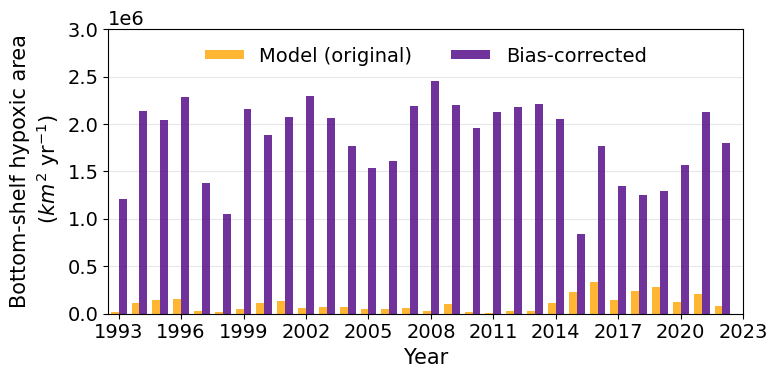

In [64]:
## plot bar comparison for every summer

outname = f'plot_{gtx}_WA-OR_bot_annual_hypoxic_area_bar_{year_list[0]}_{year_list[-1]}.png'
outfile = fig_dir / outname

pfun.start_plot(figsize=(8,4))
fig = plt.figure()
ax = fig.add_subplot()

# Select April–September
ds_summer = ds_daily.sel(
    ocean_time=ds_daily.ocean_time.dt.month.isin(range(4, 10))
)

# Sum daily hypoxic area for each year
ds_annual = ds_summer[
    ['hyp_area', 'hyp_area_corrected']
].groupby('ocean_time.year').sum(
    dim='ocean_time', skipna=True, min_count=1
)


years = ds_annual.year.values
width = 0.38

# Original model
ax.bar(
    years - width/2,
    ds_annual['hyp_area'].values / 1e6,
    width=width,
    color='orange',
    alpha=0.8,
    label='Model (original)'
)

# Bias-corrected model
ax.bar(
    years + width/2,
    ds_annual['hyp_area_corrected'].values / 1e6,
    width=width,
    color='indigo',
    alpha=0.8,
    label='Bias-corrected'
)

ax.set_xlim(1992.5, 2022.5)
ax.set_xticks(np.arange(1993, 2024, 3))
ax.set_ylim(bottom=0, top=3000000)

ax.set_ylabel('Bottom-shelf hypoxic area\n ($km^{2}$ yr$^{-1}$)', fontsize=15)
ax.set_xlabel('Year', fontsize=15)

# ax.set_title(
#     'Bathymetry: 15–200 m, lat: 42–48$^{\circ}$N'
# )

ax.legend(loc='upper center', ncol=2, frameon=False, handleheight=0.35)
ax.grid(axis='y', alpha=0.3)
ax.set_axisbelow(True)

plt.tight_layout()
plt.savefig(outfile, dpi=300)
plt.show()
pfun.end_plot()

In [65]:
area_original = ds_annual['hyp_area'].sum().values
area_corrected = ds_annual['hyp_area_corrected'].sum().values

fold_change = area_corrected / area_original

print(f'Fold change: {fold_change:.2f}')

Fold change: 17.67


In [17]:
orig = ds_daily['hyp_area'].values
corr = ds_daily['hyp_area_corrected'].values

thresh = 50e6   # example: only days with original area > 1 km^2 if units are m^2

pct_change = np.full_like(orig, np.nan, dtype=float)

mask = np.isfinite(orig) & np.isfinite(corr) & (orig > thresh)
pct_change[mask] = (corr[mask] - orig[mask]) / orig[mask] * 100

mean_pct = np.nanmean(pct_change)
min_pct  = np.nanmin(pct_change)
max_pct  = np.nanmax(pct_change)
median_pct = np.nanmedian(pct_change)

print(f'% change → mean: {mean_pct:.2f}%, median: {median_pct:.2f}%, '
      f'min: {min_pct:.2f}%, max: {max_pct:.2f}%')

% change → mean: 4335.62%, median: 1870.07%, min: -90.10%, max: 43620.13%


In [18]:
mean_pct = np.nanmean(pct_change)
min_pct  = np.nanmin(pct_change)
max_pct  = np.nanmax(pct_change)

print(f'% change → mean: {mean_pct:.2f}%, '
      f'min: {min_pct:.2f}%, max: {max_pct:.2f}%')

% change → mean: 4335.62%, min: -90.10%, max: 43620.13%


In [20]:
# select the recent 10 years of data to plot
dt = ds_yearly.sel(year=slice('2013', None))

gridname = 'cas2k'
pth = Ldir['LOo'] / 'pgrid' /gridname
in_fn = pth/'grid.nc'
# load the data
grid = xr.open_dataset(in_fn)

h = grid.h.sel(eta_rho=dt.eta_rho, xi_rho=dt.xi_rho)

In [22]:
hyp_days_mean = dt['hyp_days'].mean(dim='year', skipna=True)
hyp_days_corr_mean = dt['hyp_days_corrected'].mean(dim='year', skipna=True)
hyp_days_delta = hyp_days_corr_mean - hyp_days_mean

hyp_area_total_mean = dt['hyp_area_total'].mean(dim='year', skipna=True)
hyp_area_total_corr_mean = dt['hyp_area_total_corrected'].mean(dim='year', skipna=True)
hyp_area_total_delta = hyp_area_total_corr_mean - hyp_area_total_mean

In [23]:
hyp_area_total_mean /= 1e6
hyp_area_total_corr_mean /= 1e6
hyp_area_total_delta /= 1e6

In [24]:
# =========================================================
# Mask zeros for plotting
# =========================================================
hyp_days_mean_plot = hyp_days_mean.where(hyp_days_mean > 0)
hyp_days_corr_mean_plot = hyp_days_corr_mean.where(hyp_days_corr_mean > 0)

hyp_area_total_mean_plot = hyp_area_total_mean.where(hyp_area_total_mean > 0)
hyp_area_total_corr_mean_plot = hyp_area_total_corr_mean.where(hyp_area_total_corr_mean > 0)

# Mask difference only where both original and corrected are zero
mask_days = (hyp_days_mean > 0) | (hyp_days_corr_mean > 0)
hyp_days_delta_plot = hyp_days_delta.where(mask_days)

mask_area = (hyp_area_total_mean > 0) | (hyp_area_total_corr_mean > 0)
hyp_area_total_delta_plot = hyp_area_total_delta.where(mask_area)

In [25]:
hyp_days_pct_change = xr.where(
    hyp_days_mean > 20,
    (hyp_days_corr_mean - hyp_days_mean) / hyp_days_mean * 100,
    np.nan
)


hyp_area_pct_change = xr.where(
    hyp_area_total_mean > 50,
    (hyp_area_total_corr_mean - hyp_area_total_mean) / hyp_area_total_mean * 100,
    np.nan
)

mean_pct_area = float(hyp_area_pct_change.mean(skipna=True))
min_pct_area  = float(hyp_area_pct_change.min(skipna=True))
max_pct_area  = float(hyp_area_pct_change.max(skipna=True))

print(f'Area % change → mean: {mean_pct_area:.2f}%, '
      f'min: {min_pct_area:.2f}%, max: {max_pct_area:.2f}%')

mean_pct_days = float(hyp_days_pct_change.mean(skipna=True))
min_pct_days  = float(hyp_days_pct_change.min(skipna=True))
max_pct_days  = float(hyp_days_pct_change.max(skipna=True))

print(f'Days % change → mean: {mean_pct_days:.2f}%, '
      f'min: {min_pct_days:.2f}%, max: {max_pct_days:.2f}%')

#### Plot Figure 8

In [21]:
# Load coastline data
dir0 = Ldir['data']
fn = str(dir0) + '/coast/coast_pnw.p'
C = pd.read_pickle(fn)
C.loc[(C['lat'] < 42) | (C['lat'] > 52), 'lat'] = np.nan
C.loc[C['lon'] < -128, 'lon'] = np.nan

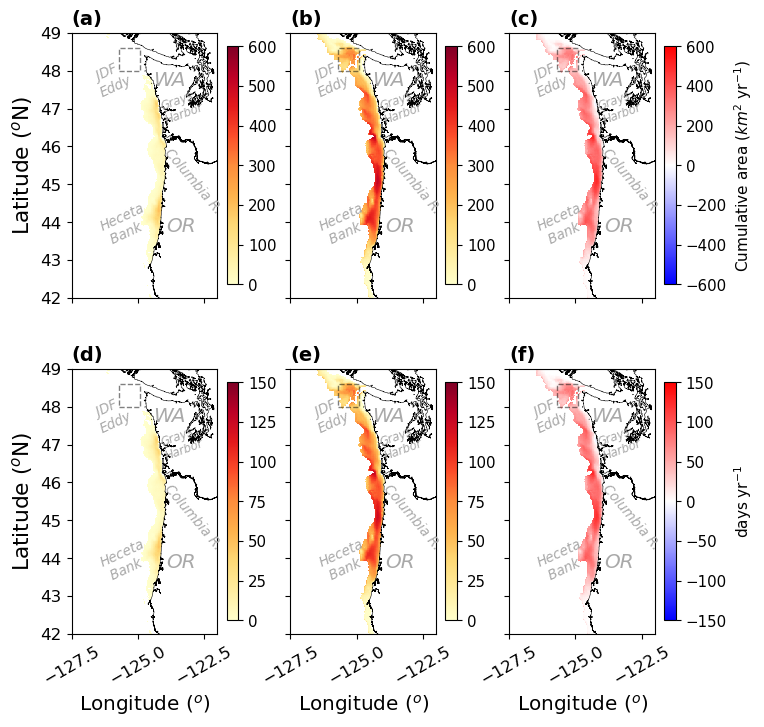

Saved: /b1/yifan/LO_output/extract/cas2k_v4_lo2b/box/bias_corrected/with_hake_hpic_trawl/cid_split_cast_balanced_z_fraction_hypoxia_two_tier_shelf_aware_no_NO3/figures/map_hyp_days_hyp_area_total_mean_2x3.png


In [31]:
# plotting
import matplotlib.patches as patches
# =========================================================
# Coordinates / map data
# =========================================================
lon = dt['Lon']
lat = dt['Lat']
h = grid.h.sel(eta_rho=dt.eta_rho, xi_rho=dt.xi_rho)
# =========================================================
# Plot settings
# =========================================================
fs = 12
zoom = True

fig, axes = plt.subplots(2, 3, figsize=(8, 8), constrained_layout=False)
fig.patch.set_facecolor('white')

fields = [

    hyp_area_total_mean_plot, hyp_area_total_corr_mean_plot, hyp_area_total_delta_plot,
    hyp_days_mean_plot, hyp_days_corr_mean_plot, hyp_days_delta_plot,
]

titles = [
    '(a)',
    '(b)',
    '(c)',
    '(d)',
    '(e)',
    '(f)'
]

# shared limits for top row
days_vmin = 0
days_vmax = np.nanmax([
    hyp_days_mean_plot.values,
    hyp_days_corr_mean_plot.values
])

# shared limits for bottom row
area_vmin = 0
area_vmax = np.nanmax([
    hyp_area_total_mean_plot.values,
    hyp_area_total_corr_mean_plot.values
])

# symmetric limits for difference panels
days_diff_max = np.nanmax(np.abs(hyp_days_delta_plot.values))
area_diff_max = np.nanmax(np.abs(hyp_area_total_delta_plot.values))

cmaps = [
    'YlOrRd', 'YlOrRd', 'bwr',
    'YlOrRd', 'YlOrRd', 'bwr',
]
# for cmap in cmaps:
#     cmap.set_bad('none')

norms = [

    None,
    None,
    TwoSlopeNorm(vmin=-600, vcenter=0, vmax=600),
    None,
    None,
    TwoSlopeNorm(vmin=-150, vcenter=0, vmax=150),
]

# vmins = [area_vmin, area_vmin, None,days_vmin, days_vmin, None]
# vmaxs = [area_vmax, area_vmax, None,days_vmax, days_vmax, None]

vmins = [0, 0, None,0, 0, None]
vmaxs = [600, 600, None,150, 150, None]

mappables = []

for i, (ax, field, title, cmap, norm, vmin, vmax) in enumerate(
    zip(axes.flat, fields, titles, cmaps, norms, vmins, vmaxs)
    ):
    row_idx = i // 3
    col_idx = i % 3
    ax.set_facecolor('white')

    if norm is None:
        pcm = ax.pcolormesh(
            lon, lat, field,
            shading='auto',
            cmap=cmap,
            vmin=vmin,
            vmax=vmax
        )
    else:
        pcm = ax.pcolormesh(
            lon, lat, field,
            shading='auto',
            cmap=cmap,
            norm=norm
        )
    # Add colorbar per subplot
    cbar = fig.colorbar(pcm, ax=ax, shrink=0.85)
    if i == 5:
        cbar.set_label(r'days yr$^{-1}$', fontsize=11)

    elif i == 2:
        cbar.set_label('Cumulative area ($km^{2}$ yr$^{-1}$)', fontsize=11)

    cbar.ax.tick_params(labelsize=fs*0.9)
    ax.set_title(title, fontsize=fs+2, fontweight='bold', loc='left')

    # define box (lon_min, lat_min, width, height)
    lon0, lat0 = -125.7, 48      # lower-left corner
    width = 0.8                  # degrees longitude
    height = 0.6                 # degrees latitude
    # JDF eddy
    rect = patches.Rectangle(
        (lon0, lat0),
        width,
        height,
        linewidth=1,
        edgecolor='black',
        facecolor='none',
        linestyle='--',
        alpha=0.5,

    )
    ax.add_patch(rect)

    # Map cosmetics
    pfun.dar(ax)
    # pfun.add_bathy_contours(ax,dt)
    # # Bathymetry
    depth_levs = [50, 100, 200]
    ax.contour(
    lon, lat, h,
    levels=depth_levs,
    colors='k',
    linewidths=2,
    zorder=100,
    transform=ax.transAxes
    )
    if zoom:
        ax.axis([-127.5, -122, 42, 49])
        ax.text(.65, .25, 'OR', fontsize=fs*1.2, color='darkgray',
                fontstyle='italic', transform=ax.transAxes)
        ax.text(.56, .8, 'WA', fontsize=fs*1.2, color='darkgray',
                fontstyle='italic', transform=ax.transAxes)
        ax.text(.13, .76, ' JDF\nEddy', fontsize = fs*0.8, color = 'darkgray',  fontstyle='italic', transform=ax.transAxes, rotation=25)
        ax.text(.6, .66, f'Grays\nHarbor', fontsize = fs*0.7, color = 'darkgray',  fontstyle='italic', transform=ax.transAxes, rotation=20)

        ax.text(.62, .32,  'Columbia R.', fontsize = fs*0.8, color = 'darkgray',  fontstyle='italic', transform=ax.transAxes, rotation=-50)
        ax.text(.18, .20, f'Heceta\n Bank', fontsize = fs*0.8, color = 'darkgray',  fontstyle='italic', transform=ax.transAxes, rotation=25)
        # ax.text(.25, .93, 'BC', fontsize=fs*1.3, color='black',
        #         fontstyle='italic', transform=ax.transAxes)
    else:
        ax.axis([-130, -122, 42, 52])

    # Coastline
    ax.plot(C['lon'].values, C['lat'].values, '-', color='k', linewidth=0.4)


    # Tick size
    ax.tick_params(axis='both', labelsize=fs*1.0)

    # Y-axis: only first column
    if col_idx == 0:
        ax.set_ylabel('Latitude ($^{o}$N)', fontsize=fs*1.3)
    else:
        ax.set_ylabel('')
        ax.tick_params(labelleft=False)

    # X-axis: only bottom row
    if row_idx == 1:
        ax.set_xlabel('Longitude ($^{o}$)', fontsize=fs*1.2)
        for tick in ax.get_xticklabels():
            tick.set_rotation(30)
            tick.set_ha('center')
    else:
        ax.set_xlabel('')
        ax.tick_params(labelbottom=False)

    mappables.append(pcm)

# Save
# =========================================================
out_png = "map_hyp_days_hyp_area_total_mean_2x3.png"
plt.savefig(f"{fig_dir}/{out_png}", dpi=300, bbox_inches='tight')
plt.show()

print("Saved:", f"{fig_dir}/{out_png}")

In [29]:
print("lon shape:", np.shape(lon))
print("lat shape:", np.shape(lat))
print("h shape:", np.shape(h))
print("h range:", np.nanmin(h), np.nanmax(h))

lon shape: (389, 190)
lat shape: (389, 190)
h shape: (389, 190)
h range: 4.0 4851.546486486485
